# Regime-Aware Portfolio Optimizer

## 1. Data

In [20]:
import os
import cmath as math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yfinance as yf
from sklearn.cluster import KMeans
from pypfopt import expected_returns, risk_models
from pypfopt.efficient_frontier import EfficientFrontier

os.makedirs("outputs", exist_ok=True)
os.makedirs("data", exist_ok=True)

In [21]:
tickers = ['AAPL', 'MSFT', 'AMZN', 'GOOGL', 'TSLA', 'WMT', 'JNJ', 'JPM', 'XOM', 'DIS']
start_date = '2015-01-01'
end_date= '2025-01-01'

raw = yf.download(tickers,start=start_date,end=end_date,progress=False, auto_adjust=True)
raw = raw["Close"]
raw = raw.dropna(axis=1, how="all").dropna()
raw.to_csv("data/prices.csv")
raw.tail()

Ticker,AAPL,AMZN,DIS,GOOGL,JNJ,JPM,MSFT,TSLA,WMT,XOM
Date,,,,,,,,,,
2024-12-24,256.339752,229.050003,110.482231,194.965668,139.277832,233.964584,433.363525,462.279999,91.220367,100.614830
2024-12-26,257.153809,227.050003,110.472420,194.458679,139.019989,234.766022,432.160095,454.130005,91.328651,100.699936
2024-12-27,253.748535,223.750000,109.490883,191.635208,138.513901,232.863876,424.683075,431.660004,90.216438,100.690483
2024-12-30,250.382950,221.300003,108.754723,190.124100,136.880905,231.077576,419.060486,417.410004,89.143616,100.009621
2024-12-31,248.615784,219.389999,109.294563,188.195419,138.103241,231.454163,415.775696,403.839996,88.927071,101.721222



## 2. Efficient Frontier / Max-Sharpe Portfolio

In [55]:
mu = expected_returns.mean_historical_return(raw)
S= risk_models.sample_cov(raw)
ef= EfficientFrontier(mu,S)

max_sharpe_weight=ef.max_sharpe()
clean_weight=ef.clean_weights()

print("Max-Sharpe portfolio weights:")
for a,w in clean_weight.items():
    if w>0:
        print(f"{a}:{w:.2%}")

perf = ef.portfolio_performance(verbose=True)


Max-Sharpe portfolio weights:
AAPL:15.99%
AMZN:20.84%
JPM:9.94%
MSFT:17.78%
TSLA:7.04%
WMT:28.42%
Expected annual return: 23.9%
Annual volatility: 20.5%
Sharpe Ratio: 1.16


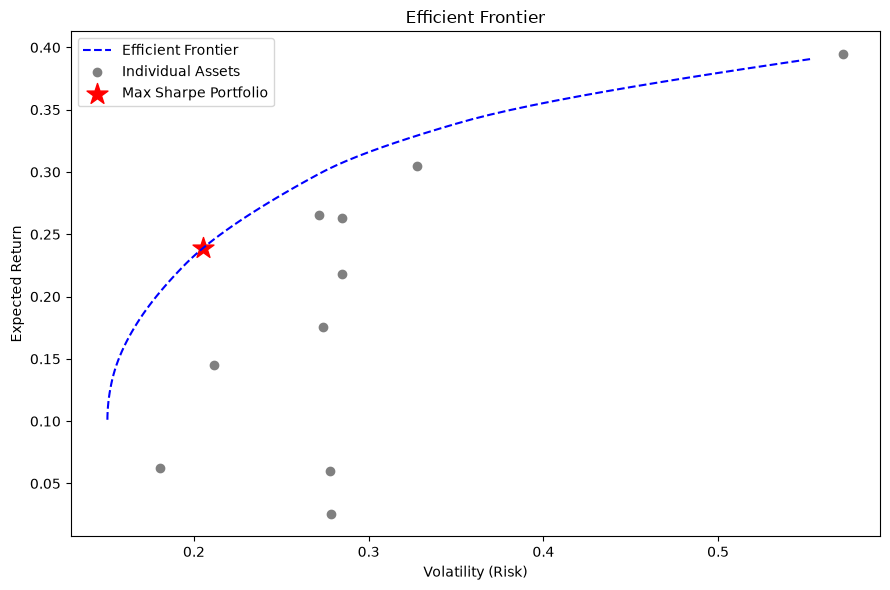

In [56]:
n = 100
risks, returns = [], []

for target in np.linspace(mu.min(), mu.max(), n):
    try:
        ef_temp= EfficientFrontier(mu,S)
        ef_temp.efficient_return(target)
        r,v,l = ef_temp.portfolio_performance()
        risks.append(v)
        returns.append(r)
    except Exception:
        continue
plt.figure(figsize=(9, 6))
plt.plot(risks, returns, "b--", label="Efficient Frontier")
plt.scatter(np.sqrt(np.diag(S)), mu, c="gray", label="Individual Assets")
plt.scatter(perf[1], perf[0], c="red", marker="*", s=250, label="Max Sharpe Portfolio")
plt.xlabel("Volatility (Risk)")
plt.ylabel("Expected Return")
plt.title("Efficient Frontier")
plt.legend()
plt.tight_layout()
plt.savefig("outputs/efficient_frontier.png", dpi=150)
plt.show()




## 3. Regime Detection

In [57]:
market = yf.download("SPY", start=start_date, end=end_date)["Close"]
market = market.squeeze()
market_returns = market.pct_change().dropna()

window = 21  
rolling_vol = market_returns.rolling(window).std() * np.sqrt(252)
rolling_ret = market_returns.rolling(window).mean() * 252

features = pd.DataFrame({
    "rolling_vol": rolling_vol,
    "rolling_ret": rolling_ret
}).dropna()

kmeans = KMeans(n_clusters=2, random_state=42, n_init=10)
features["regime"] = kmeans.fit_predict(features[["rolling_vol", "rolling_ret"]])

vol_means = features.groupby("regime")["rolling_vol"].mean()
volatile_cluster = vol_means.idxmax()

features["regime_label"] = features["regime"].apply(
    lambda x: "volatile" if x == volatile_cluster else "calm"
)

features.tail()

[*********************100%***********************]  1 of 1 completed


,rolling_vol,rolling_ret,regime,regime_label
Date,,,,
2024-12-24,0.136351,0.165429,1,calm
2024-12-26,0.135997,0.125522,1,calm
2024-12-27,0.139988,-0.063454,1,calm
2024-12-30,0.145005,-0.164030,0,volatile
2024-12-31,0.143134,-0.282233,0,volatile


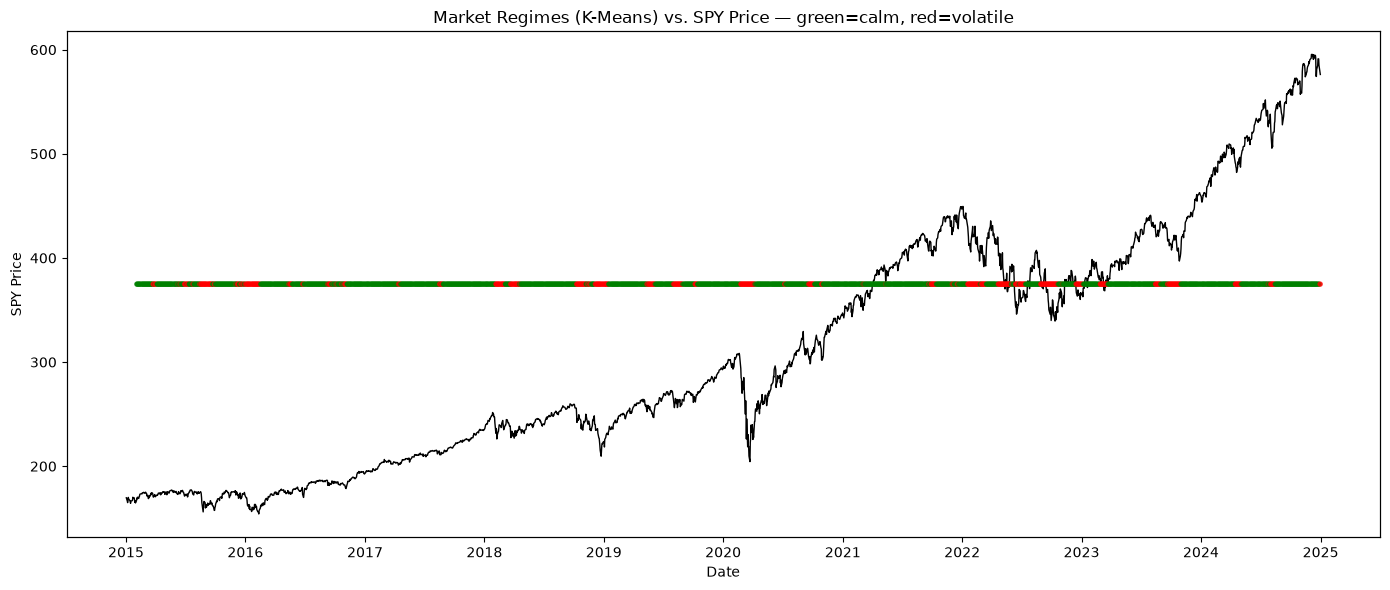

In [58]:
fig, ax1 = plt.subplots(figsize=(14, 6))

ax1.plot(market.index, market.values, color="black", linewidth=1, label="SPY Price")
ax1.set_ylabel("SPY Price")
ax1.set_xlabel("Date")

colors = features["regime_label"].map({"calm": "green", "volatile": "red"})
ax2 = ax1.twinx()
ax2.scatter(features.index, [1] * len(features), c=colors, s=8, alpha=0.5)
ax2.set_yticks([])

plt.title("Market Regimes (K-Means) vs. SPY Price — green=calm, red=volatile")
plt.tight_layout()
plt.savefig("outputs/regime_timeline.png", dpi=150)
plt.show()

## 4. Sanity Check

In [59]:
check_periods = {
    "COVID crash (Mar 2020)": ("2020-02-15", "2020-04-15"),
    "2022 rate hikes": ("2022-01-01", "2022-10-01"),
}

for name, (start, end) in check_periods.items():
    subset = features.loc[start:end]
    if len(subset):
        pct_volatile = (subset["regime_label"] == "volatile").mean()
        print(f"{name}: {pct_volatile:.0%} of days labeled 'volatile'")
    else:
        print(f"{name}: no data in this range for the tickers/date window used")

COVID crash (Mar 2020): 78% of days labeled 'volatile'
2022 rate hikes: 59% of days labeled 'volatile'
